# Ctrl+5 - Final Notebook (Datathon, Tech-Triathlon 2026)
**Waypoint Group: delivery service time, lateness, demand forecast and peak-day allocation**

Everything is in this notebook and runs top to bottom: data loading, label construction, preprocessing, model choice, training, evaluation, saving the models, the submission files, and an inference demo at the end.

| # | Section |
|---|---|
| 1 | Setup and data loading |
| 2 | Label construction (Task 1) |
| 3 | Preprocessing and feature engineering |
| 4 | Task 1: model comparison, LightGBM training, evaluation, final model, submission |
| 5 | Task 2A: demand data, model comparison, training, backtests, final model, submission |
| 6 | Task 2B: capacity analysis, optimisation, feasibility check, submission |
| 7 | Inference demo: load the saved `.pkl` models and predict |

Exploratory analysis is in `01_EDA_and_Labels.ipynb`. Run from the folder that contains `data/`. Random seed = 42.

## 1. Setup and data loading

In [2]:
import os, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import pulp
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_absolute_error, mean_squared_error, roc_auc_score,
                             log_loss, brier_score_loss)
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
D = "data/"
for d in ["models", "submissions"]:
    os.makedirs(d, exist_ok=True)

deliv   = pd.read_csv(D + "Training Data/deliveries_train.csv")
legs    = pd.read_csv(D + "Training Data/route_legs_train.csv")
t1_in   = pd.read_csv(D + "Test Data/task1_test_inputs.csv")
legs_te = pd.read_csv(D + "Test Data/route_legs_test.csv")
for name, df in [("deliveries_train", deliv), ("route_legs_train", legs),
                 ("task1_test_inputs", t1_in), ("route_legs_test", legs_te)]:
    print(f"{name:18s} {df.shape}")
print("\ndispatch status:", deliv.dispatch_status.value_counts().to_dict())
print("duplicate delivery_id:", deliv.delivery_id.duplicated().sum(),
      "| blanks only in not_run orders:", deliv[deliv.dispatch_status != "not_run"].isna().sum().sum() == 0)

deliveries_train   (92307, 20)
route_legs_train   (91894, 22)
task1_test_inputs  (5014, 20)
route_legs_test    (5014, 18)

dispatch status: {'attempted': 90351, 'deferred': 1543, 'not_run': 413}
duplicate delivery_id: 0 | blanks only in not_run orders: True


## 2. Label construction (Task 1)
Neither target is given, so we build them from the actual times in route_legs_train.csv.

1. **Join** each order to its route leg: route_id + seq_in_route = route_id + seq.
2. **Service time** = leave_outlet_time - max(arrival_time, window_open_time). A truck that arrives early waits for the window to open, and waiting is not handling.
3. **Late** = 1 if arrival_time > window_close_time.

In [3]:
CAT_COLS = ["brand", "district", "depot", "temp_requirement", "vehicle_type",
            "vehicle_temp", "dock_type", "parking_constraint", "road_class",
            "outlet_id", "vehicle_id"]


def to_min(s):
    """'HH:MM' -> minutes after midnight (NaN-safe)."""
    p = s.str.split(":", expand=True)
    return p[0].astype(float) * 60 + p[1].astype(float)


def load_reference():
    ref = {
        "outlets": pd.read_csv(D + "General Data/outlets.csv"),
        "vehicles": pd.read_csv(D + "General Data/vehicles.csv"),
        "calendar": pd.read_csv(D + "General Data/calendar.csv"),
        "dtravel": pd.read_csv(D + "General Data/district_travel.csv"),
        "allow": pd.read_csv(D + "General Data/service_allowance.csv"),
        "traffic": pd.read_csv(D + "General Data/traffic_speed.csv"),
        "road": pd.read_csv(D + "General Data/road_conditions.csv"),
    }
    return ref


def join_orders_legs(orders, legs):
    """One row per delivery: order record + its matching route leg."""
    o = orders[orders.route_id.notna()].copy()
    o["seq_in_route"] = o.seq_in_route.astype(int)
    df = o.merge(legs, left_on=["route_id", "seq_in_route"],
                 right_on=["route_id", "seq"], suffixes=("", "_leg"), how="left")
    assert df.leg_id.notna().all(), "every dispatched order must match a leg"
    return df

**The label rules.** These only work on training data, because only training data has actual times.

In [4]:
def add_labels(df):
    """Task 1 labels - only possible where actual times exist (training)."""
    arr = to_min(df.arrival_time)
    leave = to_min(df.leave_outlet_time)
    wopen = to_min(df.window_open_time)
    wclose = to_min(df.window_close_time)
    df["service_min"] = leave - np.maximum(arr, wopen)   # waiting is not handling
    df["late"] = (arr > wclose).astype(int)
    return df

In [5]:
train = add_labels(join_orders_legs(deliv, legs))
print("labelled deliveries:", len(train), "(not_run orders have no leg and are excluded)")

# proof the waiting rule matters: early trucks look slow only with the naive label
arr, wopen = to_min(train.arrival_time), to_min(train.window_open_time)
early = arr < wopen
print(pd.DataFrame({"naive: leave - arrival": (to_min(train.leave_outlet_time) - arr).groupby(early).median(),
                    "our label": train.service_min.groupby(early).median()})
        .rename(index={False: "not early", True: "arrived early (4.4%)"}))
print("\nlate rate:", round(train.late.mean(), 3))
print(train.groupby("brand").agg(service_median=("service_min", "median"), late_rate=("late", "mean")).round(3))

labelled deliveries: 91894 (not_run orders have no leg and are excluded)
                      naive: leave - arrival  our label
not early                               15.0       15.0
arrived early (4.4%)                    30.0       13.0

late rate: 0.196
       service_median  late_rate
brand                           
Fresh            15.0      0.204
Style            46.0      0.055
Tech             52.0      0.025


## 3. Preprocessing and feature engineering
One function, `build_features()`, is applied to **both** train and test, so both always get exactly the same steps.

**No leakage:** we only use what is known before the truck leaves: planned times, order, outlet, vehicle, calendar, the hourly traffic profile, and the day's road conditions. Actual times are used only for labels.

Main engineered features (all chosen from the EDA):
- `planned_slack` = window close - planned arrival. This is the strongest single signal.
- `slow_factor` = 100 / (traffic speed index x road disruption index / 100), and `slack_after_traffic` = slack minus the extra travel expected from congestion.
- Route position: stop number, stops left, cumulative planned travel, allowance of earlier stops.
- Load: order size, route load vs vehicle capacity.
- Calendar: payday, days since payday, festival ramp, holiday, weekday, month.

**Step 1:** add outlet access, the standard handling allowance, district road info and vehicle capacity.

In [6]:
def add_outlet_vehicle_info(out, ref):
    """Step 1 - outlet access, standard handling allowance, district road info, vehicle capacity."""
    o = ref["outlets"][["outlet_id", "dock_type", "parking_constraint", "mall_window"]]
    out = out.merge(o, on="outlet_id", how="left")
    out["is_mall"] = out.mall_window.notna().astype(int)
    out = out.merge(ref["allow"], on=["brand", "dock_type"], how="left")
    out = out.merge(ref["dtravel"][["district", "road_class", "free_flow_kmh",
                                    "depot_to_district_km", "inter_stop_km"]], on="district", how="left")
    out = out.merge(ref["vehicles"][["vehicle_id", "weight_cap_kg", "volume_cap_m3"]], on="vehicle_id", how="left")
    return out

**Step 2:** planned times and **planned slack** (how many minutes the plan leaves before the window closes).

In [7]:
def add_time_window_features(out):
    """Step 2 - planned clock times and how much slack the plan leaves before the window closes."""
    for c in ["planned_depart_time", "planned_arrival_time", "window_open_time", "window_close_time"]:
        out[c.replace("_time", "_m")] = to_min(out[c])
    out["window_len"] = out.window_close_m - out.window_open_m
    out["planned_slack"] = out.window_close_m - out.planned_arrival_m      # >0 = buffer before close
    out["planned_wait"] = (out.window_open_m - out.planned_arrival_m).clip(lower=0)
    out["arr_hour"] = (out.planned_arrival_m // 60).astype(int)
    out["dep_hour"] = (out.planned_depart_m // 60).astype(int)
    return out

**Step 3:** the stop's position in its route. Delays build up, so later stops are more at risk.

In [8]:
def add_route_context(out, legs_all, ref):
    """Step 3 - where the stop sits in its route (planned columns only): delays build up along a route."""
    L = legs_all[["route_id", "seq", "to_outlet", "distance_km", "planned_depart_time",
                  "planned_travel_duration_min", "planned_arrival_time", "brand"]].copy()
    L = L.merge(ref["outlets"][["outlet_id", "dock_type"]], left_on="to_outlet",
                right_on="outlet_id", how="left").merge(ref["allow"], on=["brand", "dock_type"], how="left")
    L = L.sort_values(["route_id", "seq"])
    L["cum_travel"] = L.groupby("route_id").planned_travel_duration_min.cumsum()
    L["cum_dist"] = L.groupby("route_id").distance_km.cumsum()
    L["prev_allow"] = L.groupby("route_id").service_allowance_min.cumsum() - L.service_allowance_min
    g = L.groupby("route_id")
    route = pd.DataFrame({"n_stops": g.size(),
                          "route_start_m": g.planned_depart_time.first().pipe(to_min),
                          "route_dist": g.distance_km.sum()})
    out = out.merge(L[["route_id", "seq", "cum_travel", "cum_dist", "prev_allow"]], on=["route_id", "seq"], how="left")
    out = out.merge(route, left_on="route_id", right_index=True, how="left")
    out["stops_before"] = out.seq
    out["stops_left"] = out.n_stops - out.seq - 1
    out["planned_elapsed"] = out.planned_arrival_m - out.route_start_m
    out["first_leg"] = (out.seq == 0).astype(int)
    return out

**Step 4:** order size and how full the vehicle is.

In [9]:
def add_load_features(out, df):
    """Step 4 - order size and how full the vehicle is on this route."""
    load = df.groupby("route_id").agg(route_vol=("order_volume_m3", "sum"),
                                      route_wt=("order_weight_kg", "sum"),
                                      route_units=("order_units", "sum"))
    out = out.merge(load, left_on="route_id", right_index=True, how="left")
    out["vol_util"] = out.route_vol / out.volume_cap_m3
    out["wt_util"] = out.route_wt / out.weight_cap_kg
    out["kg_per_unit"] = out.order_weight_kg / out.order_units.clip(lower=1)
    out["m3_per_unit"] = out.order_volume_m3 / out.order_units.clip(lower=1)
    return out

**Step 5:** calendar effects: payday, festival build-up, holidays.

In [10]:
def add_calendar_features(out, ref):
    """Step 5 - payday, festival build-up, holidays, month."""
    cal = ref["calendar"][["date", "is_payday", "festival_ramp", "is_holiday", "is_weekend"]].copy()
    cal["d"] = pd.to_datetime(cal.date)
    cal = cal.sort_values("d")
    pay_dates = cal.loc[cal.is_payday == 1, "d"]
    cal["days_since_payday"] = cal.d.apply(lambda x: (x - pay_dates[pay_dates <= x].max()).days
                                           if (pay_dates <= x).any() else 30)
    out = out.merge(cal.drop(columns="d"), on="date", how="left")
    dt = pd.to_datetime(out.date)
    out["month"] = dt.dt.month
    out["dom"] = dt.dt.day
    return out

**Step 6:** traffic and road disruption. This gives `slack_after_traffic`, the slack left once the expected congestion is taken off.

In [11]:
def add_traffic_features(out, ref):
    """Step 6 - traffic at the planned departure hour + road disruption that day -> expected slow-down."""
    out = out.merge(ref["traffic"].rename(columns={"hour": "dep_hour"}),
                    on=["district", "dep_hour", "monsoon"], how="left")
    out = out.merge(ref["road"], on=["district", "date"], how="left")
    out["slow_factor"] = 100 / (out.speed_index * out.disruption_index / 100)
    out["exp_travel"] = out.planned_travel_duration_min * out.slow_factor
    out["exp_cum_travel"] = out.cum_travel * out.slow_factor
    out["slack_after_traffic"] = out.planned_slack - (out.exp_cum_travel - out.cum_travel)   # our key feature
    return out

**The full pipeline:** all 6 steps in order. The same function is used for train and test.

In [12]:
def build_features(df, legs_all, ref):
    """
    The full preprocessing pipeline - the SAME steps for train and test.
    df       : joined orders + legs
    legs_all : all legs of the same routes (for route-level context)
    """
    out = add_outlet_vehicle_info(df.copy(), ref)
    out = add_time_window_features(out)
    out = add_route_context(out, legs_all, ref)
    out = add_load_features(out, df)
    out = add_calendar_features(out, ref)
    out = add_traffic_features(out, ref)
    for c in CAT_COLS:
        out[c] = out[c].astype("category")
    return out


NUM_FEATURES = [
    "order_units", "order_weight_kg", "order_volume_m3", "kg_per_unit", "m3_per_unit",
    "service_allowance_min", "is_mall", "weight_cap_kg", "volume_cap_m3",
    "distance_km", "planned_travel_duration_min", "planned_depart_m", "planned_arrival_m",
    "window_open_m", "window_close_m", "window_len", "planned_slack", "planned_wait",
    "arr_hour", "dep_hour", "seq", "n_stops", "stops_left", "first_leg",
    "cum_travel", "cum_dist", "prev_allow", "route_start_m", "route_dist", "planned_elapsed",
    "route_vol", "route_wt", "route_units", "vol_util", "wt_util",
    "free_flow_kmh", "depot_to_district_km", "inter_stop_km",
    "monsoon", "dow", "month", "dom", "is_payday", "festival_ramp", "is_holiday",
    "is_weekend", "days_since_payday",
    "speed_index", "disruption_index", "slow_factor", "exp_travel", "exp_cum_travel",
    "slack_after_traffic",
]


FEATURES = NUM_FEATURES + CAT_COLS

In [13]:
ref = load_reference()
tr = build_features(train, legs, ref)
te = build_features(join_orders_legs(t1_in, legs_te), legs_te, ref)
print("train:", tr[FEATURES].shape, "| test:", te[FEATURES].shape)
print("missing values -> train:", int(tr[FEATURES].isna().sum().sum()), "| test:", int(te[FEATURES].isna().sum().sum()))
print(len(NUM_FEATURES), "numeric +", len(CAT_COLS), "categorical features")

train: (91894, 64) | test: (5014, 64)
missing values -> train: 0 | test: 0
53 numeric + 11 categorical features


## 4. Task 1: predict service time and late probability

### 4.1 Validation design
We hold out the **last 6 weeks of history** (2026-01-03 to 2026-02-14), the same length as the test period. A random split would leak future conditions into training.

In [14]:
CUT = "2026-01-03"
a, b = tr[tr.date < CUT], tr[tr.date >= CUT]
print("train rows:", len(a), "| validation rows:", len(b), "| validation late rate:", round(b.late.mean(), 3))

train rows: 86721 | validation rows: 5173 | validation late rate: 0.131


### 4.2 Which model? Comparing baselines, linear models, a decision tree, a random forest and LightGBM
- **Baselines** are simple guesses we must beat: the dispatcher's standard handling allowance for service time, and "less slack means riskier" for lateness.
- **Linear models** (Ridge / Logistic Regression) are simple and explainable.
- **A single decision tree** is easy to read, but it either stays too simple or memorises the training data.
- **A random forest** is many deep trees voting.
- **LightGBM** (gradient-boosted decision trees, trained from scratch) builds hundreds of small trees, each one correcting the mistakes of the previous ones. It handles mixed numeric and categorical data and learns interactions such as *little slack x heavy traffic x festival*.

In [15]:
# linear models need one-hot encoded categories + scaling
def linear_X(df, cols):
    return pd.get_dummies(df[FEATURES], columns=CAT_COLS, dtype=float).reindex(columns=cols, fill_value=0)
lin_cols = pd.get_dummies(a[FEATURES], columns=CAT_COLS, dtype=float).columns
Xa, Xb = linear_X(a, lin_cols), linear_X(b, lin_cols)

ridge = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(Xa, a.service_min)
logit = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000)).fit(Xa, a.late)

comparison = pd.DataFrame({
    "service MAE (min)": {"Baseline (allowance / slack rule)": mean_absolute_error(b.service_min, b.service_allowance_min),
                          "Linear (Ridge / Logistic)": mean_absolute_error(b.service_min, ridge.predict(Xb))},
    "late AUC": {"Baseline (allowance / slack rule)": roc_auc_score(b.late, -b.planned_slack),
                 "Linear (Ridge / Logistic)": roc_auc_score(b.late, logit.predict_proba(Xb)[:, 1])},
    "late log-loss": {"Baseline (allowance / slack rule)": log_loss(b.late, np.full(len(b), a.late.mean())),
                      "Linear (Ridge / Logistic)": log_loss(b.late, logit.predict_proba(Xb)[:, 1])},
})

# tree models in scikit-learn need categories as numbers
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
def tree_X(df):
    X = df[FEATURES].copy()
    for c in CAT_COLS: X[c] = X[c].cat.codes
    return X
Ta, Tb = tree_X(a), tree_X(b)
for name, r, c in [
    ("Single decision tree", DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=SEED),
                             DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEED)),
    ("Random forest (100 trees)", RandomForestRegressor(100, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
                                  RandomForestClassifier(100, min_samples_leaf=5, n_jobs=-1, random_state=SEED))]:
    r.fit(Ta, a.service_min); c.fit(Ta, a.late)
    pl = np.clip(c.predict_proba(Tb)[:, 1], 1e-4, 1 - 1e-4)
    comparison.loc[name] = [mean_absolute_error(b.service_min, r.predict(Tb)), roc_auc_score(b.late, pl), log_loss(b.late, pl)]
comparison.round(3)

,service MAE (min),late AUC,late log-loss
Baseline (allowance / slack rule),7.052,0.880,0.405
Linear (Ridge / Logistic),4.402,0.964,0.156
Single decision tree,5.067,0.958,0.174
Random forest (100 trees),4.033,0.971,0.146


### 4.3 Train LightGBM
Two models: a **regressor** for `service_min` and a **binary classifier** for `late`. We use early stopping on the validation weeks to pick the number of trees.

In [16]:
REG_PARAMS = dict(objective="regression", learning_rate=0.03, num_leaves=63, min_child_samples=30,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)


CLF_PARAMS = dict(objective="binary", learning_rate=0.03, num_leaves=63, min_child_samples=30,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)

In [17]:
reg_v = lgb.LGBMRegressor(n_estimators=3000, **REG_PARAMS)
reg_v.fit(a[FEATURES], a.service_min,
          eval_set=[(b[FEATURES], b.service_min)], eval_metric="l1",
          callbacks=[lgb.early_stopping(100, verbose=False)])

clf_v = lgb.LGBMClassifier(n_estimators=3000, **CLF_PARAMS)
clf_v.fit(a[FEATURES], a.late,
          eval_set=[(b[FEATURES], b.late)], eval_metric="binary_logloss",
          callbacks=[lgb.early_stopping(100, verbose=False)])

b = b.assign(pred_service=np.clip(reg_v.predict(b[FEATURES]), 1, None),
             pred_late=clf_v.predict_proba(b[FEATURES])[:, 1])
comparison.loc["LightGBM (ours)"] = [mean_absolute_error(b.service_min, b.pred_service),
                                    roc_auc_score(b.late, b.pred_late), log_loss(b.late, b.pred_late)]
print("trees chosen by early stopping -> regressor:", reg_v.best_iteration_, "| classifier:", clf_v.best_iteration_)
print("service RMSE:", round(mean_squared_error(b.service_min, b.pred_service) ** 0.5, 2),
      "| late Brier:", round(brier_score_loss(b.late, b.pred_late), 4))
comparison.round(3)

trees chosen by early stopping -> regressor: 298 | classifier: 291
service RMSE: 5.91 | late Brier: 0.0416


,service MAE (min),late AUC,late log-loss
Baseline (allowance / slack rule),7.052,0.880,0.405
Linear (Ridge / Logistic),4.402,0.964,0.156
Single decision tree,5.067,0.958,0.174
Random forest (100 trees),4.033,0.971,0.146
LightGBM (ours),3.730,0.974,0.134


LightGBM is the best on all three measures. It almost halves the service-time error compared with the dispatcher's allowance, beats a single decision tree and a random forest, and gives the most accurate late probabilities. This is our final model.

### 4.4 Evaluation: by brand, calibration, feature importance

            n  MAE_allowance  MAE_model  actual_late_rate  predicted_late_rate
brand                                                                         
Fresh  4926.0          6.305      3.346             0.136                0.133
Style   151.0         16.642      9.478             0.040                0.033
Tech     96.0         30.323     14.395             0.031                0.015

Calibration:
             predicted  actual     n
pred_late                           
(0.0, 0.05]      0.005   0.003  3756
(0.05, 0.1]      0.070   0.085   223
(0.1, 0.2]       0.145   0.186   253
(0.2, 0.4]       0.297   0.299   264
(0.4, 0.6]       0.500   0.480   171
(0.6, 0.8]       0.702   0.725   178
(0.8, 0.9]       0.854   0.914   105
(0.9, 1.0]       0.956   0.960   223


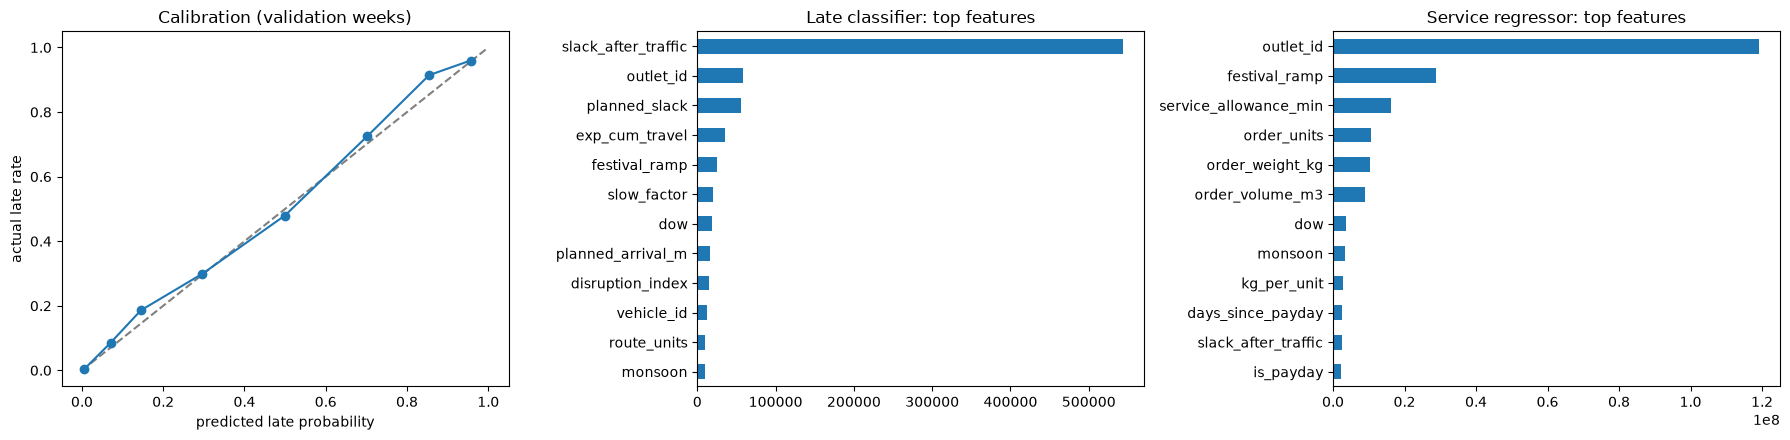

In [18]:
print(b.groupby("brand").apply(lambda g: pd.Series({
    "n": len(g), "MAE_allowance": (g.service_min - g.service_allowance_min).abs().mean(),
    "MAE_model": (g.service_min - g.pred_service).abs().mean(),
    "actual_late_rate": g.late.mean(), "predicted_late_rate": g.pred_late.mean()})).round(3))

cal_tab = b.groupby(pd.cut(b.pred_late, [0, .05, .1, .2, .4, .6, .8, .9, 1]), observed=True).agg(
    predicted=("pred_late", "mean"), actual=("late", "mean"), n=("late", "size"))
print("\nCalibration:"); print(cal_tab.round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot([0, 1], [0, 1], "--", color="grey"); ax[0].plot(cal_tab.predicted, cal_tab.actual, "o-")
ax[0].set(xlabel="predicted late probability", ylabel="actual late rate", title="Calibration (validation weeks)")
pd.Series(clf_v.booster_.feature_importance("gain"), FEATURES).sort_values().tail(12).plot(kind="barh", ax=ax[1], title="Late classifier: top features")
pd.Series(reg_v.booster_.feature_importance("gain"), FEATURES).sort_values().tail(12).plot(kind="barh", ax=ax[2], title="Service regressor: top features")
plt.tight_layout(); plt.show()

The probabilities are well calibrated: when the model says 30%, about 30% of those deliveries are late. Our engineered `slack_after_traffic` is the top lateness feature. Service time is driven by brand, dock type, order size and the outlet.

### 4.5 Final models: retrain on all history, save as .pkl, predict the test set

In [19]:
n_reg, n_clf = int(reg_v.best_iteration_ * 1.1), int(clf_v.best_iteration_ * 1.1)   # +10% trees for +6 weeks of data
reg = lgb.LGBMRegressor(n_estimators=n_reg, **REG_PARAMS).fit(tr[FEATURES], tr.service_min)
clf = lgb.LGBMClassifier(n_estimators=n_clf, **CLF_PARAMS).fit(tr[FEATURES], tr.late)

pickle.dump({"model": reg, "features": FEATURES}, open("models/task1_service_regressor.pkl", "wb"))
pickle.dump({"model": clf, "features": FEATURES}, open("models/task1_late_classifier.pkl", "wb"))

pred = pd.DataFrame({"delivery_id": te.delivery_id.values,
                     "pred_service_min": np.round(np.clip(reg.predict(te[FEATURES]), 1, None), 2),
                     "pred_late_prob": np.round(np.clip(clf.predict_proba(te[FEATURES])[:, 1], 0.001, 0.999), 4)})
tmpl = pd.read_csv(D + "Submission Templates/submission_task1.csv")
sub1 = tmpl[["delivery_id"]].merge(pred, on="delivery_id", how="left")   # keep template order
assert len(sub1) == len(tmpl) and sub1.notna().all().all()
sub1.to_csv("submissions/submission_task1.csv", index=False)
print("saved models + submissions/submission_task1.csv"); print(sub1.describe().round(3))

saved models + submissions/submission_task1.csv
       pred_service_min  pred_late_prob
count          5014.000        5014.000
mean             18.268           0.215
std              11.808           0.347
min               5.250           0.001
25%              11.730           0.001
50%              15.450           0.006
75%              20.718           0.297
max             137.840           0.999


## 5. Task 2A: weekly demand per depot and brand

### 5.1 Build the demand table
- Every order is counted once, including deferred and not_run ones, on the date the store asked for (`order_date`). We use `deliveries_train` + `task1_test_inputs`.
- We model **daily** volume on operating days and then add up each ISO week from `calendar.csv`. That way, holiday weeks with fewer operating days (for example 2026 W16, with 4 days) are handled correctly.
- Chilled volume only exists for Fresh. It's set to 0 for Style and Tech.

In [20]:
CAL_COLS = ["dow", "is_payday", "festival_ramp", "is_holiday", "monsoon", "month"]


def build_daily(deliv, t1_inputs, cal):
    """Every order counted once (incl. deferred / not_run) on the date the store requested."""
    o = pd.concat([deliv, t1_inputs], ignore_index=True)
    assert not o.delivery_id.duplicated().any()
    o["chilled_m3"] = np.where(o.temp_requirement == "chilled", o.order_volume_m3, 0.0)
    day = (o.groupby(["depot", "brand", "order_date"])
             .agg(v=("order_volume_m3", "sum"), c=("chilled_m3", "sum"))
             .reset_index().rename(columns={"order_date": "date"}))
    series = day[["depot", "brand"]].drop_duplicates()
    op = cal[cal.is_operating == 1]
    last = day.date.max()
    grid = series.merge(op[op.date <= last], how="cross")
    grid = grid.merge(day, on=["depot", "brand", "date"], how="left").fillna({"v": 0.0, "c": 0.0})
    return add_cal(grid), series


def add_cal(g):
    g = g.copy()
    d = pd.to_datetime(g.date)
    g["t"] = (d - pd.Timestamp("2024-01-01")).dt.days / 365.0
    g["month"] = d.dt.month
    return g

In [21]:
cal = ref["calendar"]
daily, series = build_daily(deliv, t1_in, cal)
print("daily rows:", daily.shape, "| history:", daily.date.min(), "to", daily.date.max())
daily.head()

daily rows: (4170, 18) | history: 2024-01-01 to 2026-03-28


,depot,brand,date,dow,dow_name,is_weekend,iso_year,iso_week,is_payday,festival,festival_ramp,is_holiday,monsoon,is_operating,v,c,t,month
0,Kandy,Fresh,2024-01-01,0,Mon,0,2024,1,0,NaN,0.0,0,0,1,73.476,24.778,0.000000,1
1,Kandy,Fresh,2024-01-02,1,Tue,0,2024,1,0,NaN,0.0,0,0,1,68.582,23.045,0.002740,1
2,Kandy,Fresh,2024-01-03,2,Wed,0,2024,1,0,NaN,0.0,0,0,1,74.383,29.427,0.005479,1
3,Kandy,Fresh,2024-01-04,3,Thu,0,2024,1,0,NaN,0.0,0,0,1,75.098,26.882,0.008219,1
4,Kandy,Fresh,2024-01-05,4,Fri,0,2024,1,0,NaN,0.0,0,0,1,85.026,28.102,0.010959,1


### 5.2 The models
Two models trained from scratch, then **averaged**:
1. **Ridge regression per depot x brand** on weekday + payday + festival ramp + holiday + monsoon + a **time trend**. It follows the growth in demand.
2. **One LightGBM for all series**, predicting volume relative to that series' average over the past year. It learns the non-linear festival and payday shape that all series share.

**Helpers:** the inputs for the Ridge model, and each series' average daily volume over the past year (past data only).

In [22]:
def ridge_X(g):
    X = pd.get_dummies(g.dow.astype(int).astype(str), prefix="dow").astype(float)
    for c in ["is_payday", "festival_ramp", "is_holiday", "monsoon", "t"]:
        X[c] = g[c].values
    X["ramp_sq"] = g.festival_ramp.values ** 2
    return X


def trailing_level(g, col):
    """mean daily volume over the previous 364 days (past only)"""
    s = g.set_index(pd.to_datetime(g.date))[col]
    return s.rolling("364D", min_periods=60).mean().shift(1).values

**Training:** one Ridge model per depot x brand (total + chilled), plus one LightGBM shared by all series.

In [23]:
def fit(daily):
    models = {"ridge": {}, "level": {}}
    parts = []
    for (dp, br), g in daily.groupby(["depot", "brand"]):
        g = g.sort_values("date").copy()
        X = ridge_X(g)
        models["ridge"][(dp, br)] = {t: Ridge(alpha=1.0).fit(X, g[t]) for t in ["v", "c"]}
        models["ridge"][(dp, br)]["cols"] = list(X.columns)
        g["lv"], g["lc"] = trailing_level(g, "v"), trailing_level(g, "c")
        models["level"][(dp, br)] = (g.v.tail(312).mean(), g.c.tail(312).mean())   # ~last year
        parts.append(g)
    H = pd.concat(parts).dropna(subset=["lv"])
    H["sid"] = (H.depot + "_" + H.brand).astype("category")
    p = dict(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=20,
             random_state=SEED, verbose=-1)
    models["lgb_v"] = lgb.LGBMRegressor(**p).fit(H[CAL_COLS + ["sid"]], H.v / H.lv.clip(lower=1e-6))
    Hf = H[H.brand == "Fresh"]
    models["lgb_c"] = lgb.LGBMRegressor(**p).fit(Hf[CAL_COLS + ["sid"]], Hf.c / Hf.lc.clip(lower=1e-6))
    return models

**Prediction:** predict each operating day, average the two models, then add up each week.

In [24]:
def predict_days(models, series, cal_days):
    F = add_cal(series.merge(cal_days[cal_days.is_operating == 1], how="cross"))
    F["sid"] = pd.Categorical(F.depot + "_" + F.brand,
                              categories=models["lgb_v"].booster_.pandas_categorical[0])
    out = []
    for (dp, br), g in F.groupby(["depot", "brand"]):
        g = g.copy()
        r = models["ridge"][(dp, br)]
        X = ridge_X(g).reindex(columns=r["cols"], fill_value=0)
        lv, lc = models["level"][(dp, br)]
        rv, rc = np.clip(r["v"].predict(X), 0, None), np.clip(r["c"].predict(X), 0, None)
        gv = models["lgb_v"].predict(g[CAL_COLS + ["sid"]]) * lv
        gc = models["lgb_c"].predict(g[CAL_COLS + ["sid"]]) * lc if br == "Fresh" else 0
        g["p_v"] = (rv + gv) / 2
        g["p_c"] = (rc + gc) / 2 if br == "Fresh" else 0.0      # chilled only exists for Fresh
        out.append(g)
    return pd.concat(out)


def to_weeks(daily_pred):
    w = daily_pred.groupby(["depot", "brand", "iso_year", "iso_week"])[["p_v", "p_c"]].sum().reset_index()
    w["p_c"] = np.minimum(w.p_c, w.p_v)
    return w

### 5.3 Backtests: compare with a simple baseline
- **A:** train up to 2025 W13 and forecast 2025 W14-W23. This is the same festival season (New Year, Vesak, Poson) we have to forecast.
- **B:** forecast the most recent 10 weeks.

Baseline: *same week last year x recent growth*.

In [25]:
def backtest(daily, series, cal, train_end, weeks):
    hist = daily[daily.date <= train_end]
    m = fit(hist)
    wk_cal = cal[[(y, w) in weeks for y, w in zip(cal.iso_year, cal.iso_week)]]
    pred = to_weeks(predict_days(m, series, wk_cal))
    truth = (daily[[(y, w) in weeks for y, w in zip(daily.iso_year, daily.iso_week)]]
             .groupby(["depot", "brand", "iso_year", "iso_week"])[["v", "c"]].sum().reset_index())
    j = truth.merge(pred, on=["depot", "brand", "iso_year", "iso_week"])
    return {"WAPE_total": (j.v - j.p_v).abs().sum() / j.v.sum(),
            "MAE_total_m3": (j.v - j.p_v).abs().mean(),
            "WAPE_chilled": (j.c - j.p_c).abs().sum() / j.c.sum()}, j

In [26]:
def seasonal_naive(daily, train_end, weeks):
    wk = daily[daily.date <= train_end].groupby(["depot", "brand", "iso_year", "iso_week"])[["v", "c"]].sum().reset_index()
    rows = []
    for (dp, br), h in wk.groupby(["depot", "brand"]):
        last = h.tail(12)
        prev = h.merge(last[["iso_year", "iso_week"]].assign(iso_year=last.iso_year - 1), on=["iso_year", "iso_week"])
        gv = last.v.sum() / prev.v.sum(); gc = last.c.sum() / prev.c.sum() if prev.c.sum() > 0 else 0
        for y, w in weeks:
            ly = h[(h.iso_year == y - 1) & (h.iso_week == w)]
            rows.append((dp, br, y, w, ly.v.sum() * gv, ly.c.sum() * gc))
    p = pd.DataFrame(rows, columns=["depot", "brand", "iso_year", "iso_week", "p_v", "p_c"])
    t = daily[[(y, w) in weeks for y, w in zip(daily.iso_year, daily.iso_week)]].groupby(["depot", "brand", "iso_year", "iso_week"])[["v", "c"]].sum().reset_index()
    j = t.merge(p, on=["depot", "brand", "iso_year", "iso_week"])
    return {"WAPE_total": (j.v - j.p_v).abs().sum() / j.v.sum(), "WAPE_chilled": (j.c - j.p_c).abs().sum() / j.c.sum()}

rows = {}
for name, end, weeks in [("A: same season 2025", "2025-03-29", [(2025, w) for w in range(14, 24)]),
                         ("B: last 10 weeks", "2026-01-17", [(2026, w) for w in range(4, 14)])]:
    ours, j = backtest(daily, series, cal, end, weeks)
    base = seasonal_naive(daily, end, weeks)
    rows[name] = {"baseline WAPE total": base["WAPE_total"], "ours WAPE total": ours["WAPE_total"],
                  "baseline WAPE chilled": base["WAPE_chilled"], "ours WAPE chilled": ours["WAPE_chilled"]}
pd.DataFrame(rows).T.round(3)

,baseline WAPE total,ours WAPE total,baseline WAPE chilled,ours WAPE chilled
A: same season 2025,0.117,0.062,0.113,0.055
B: last 10 weeks,0.048,0.042,0.038,0.033


Our model's error on the same festival season last year is about **6%**, roughly half the baseline's.

### 5.4 Final model: train on all history, save as .pkl, forecast 2026 W14-W23

depot     Kandy              Peliyagoda             
brand     Fresh  Style  Tech      Fresh  Style  Tech
iso_week                                            
14        528.0   80.0  23.0     1008.0  143.0  33.0
15        681.0  109.0  26.0     1268.0  192.0  41.0
16        361.0   53.0  21.0      678.0  125.0  22.0
17        562.0   87.0  23.0     1067.0  150.0  35.0
18        559.0   97.0  21.0     1054.0  136.0  28.0
19        517.0   77.0  21.0      985.0  137.0  30.0
20        517.0   77.0  21.0      985.0  137.0  30.0
21        531.0   80.0  21.0     1002.0  139.0  32.0
22        618.0  103.0  21.0     1164.0  172.0  35.0
23        518.0   78.0  21.0      987.0  137.0  31.0


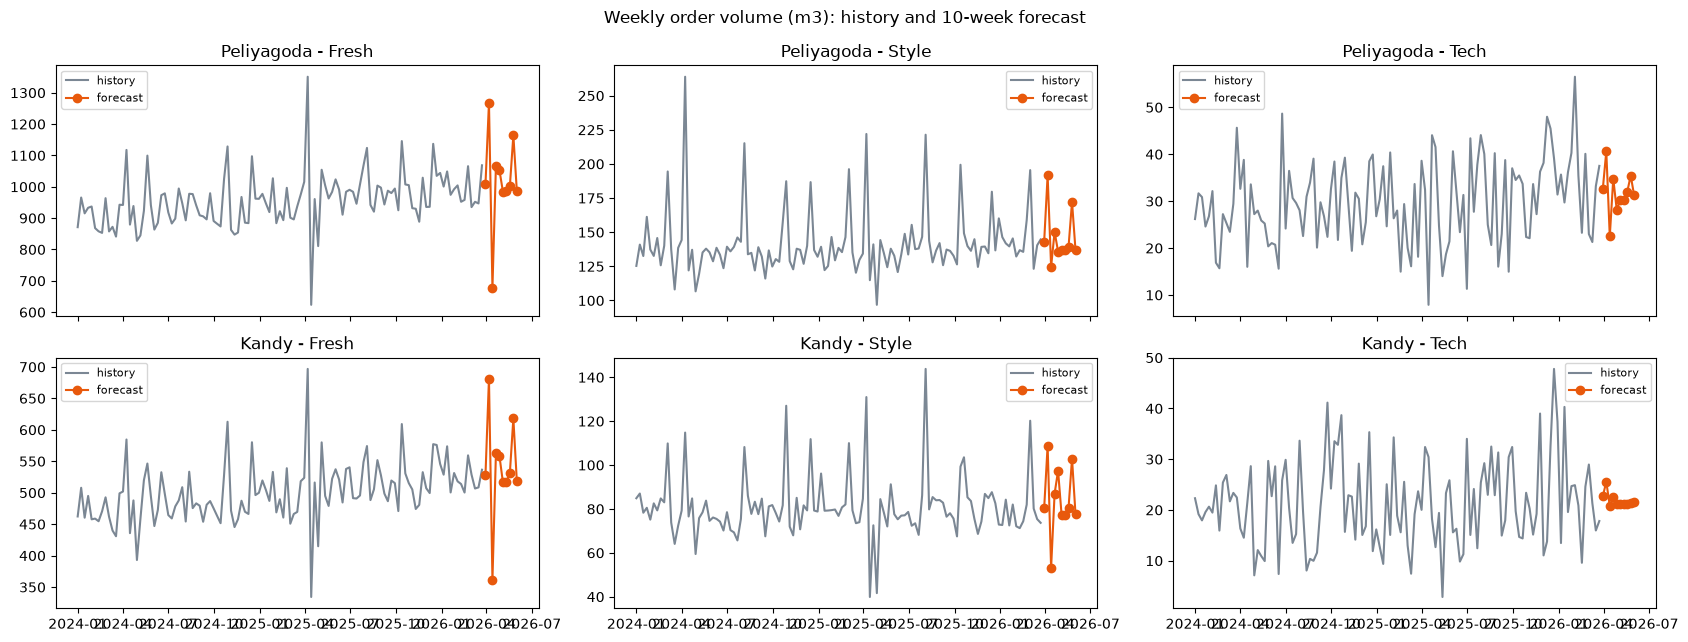

In [27]:
m2a = fit(daily)
pickle.dump(m2a, open("models/task2a_demand_models.pkl", "wb"))

t2a = pd.read_csv(D + "Test Data/task2a_test_inputs.csv")
fc_days = cal[[(y, w) in set(zip(t2a.iso_year, t2a.iso_week)) for y, w in zip(cal.iso_year, cal.iso_week)]]
wk = to_weeks(predict_days(m2a, series, fc_days))
out = t2a.merge(wk, on=["depot", "brand", "iso_year", "iso_week"], how="left")
out["pred_total_volume_m3"] = out.p_v.round(2)
out["pred_chilled_volume_m3"] = np.where(out.brand == "Fresh", out.p_c, 0).round(2)
tmpl = pd.read_csv(D + "Submission Templates/submission_task2a.csv")
sub2a = tmpl[["row_id"]].merge(out[["row_id", "pred_total_volume_m3", "pred_chilled_volume_m3"]], on="row_id")
assert len(sub2a) == len(tmpl) and sub2a.notna().all().all()
sub2a.to_csv("submissions/submission_task2a.csv", index=False)

show = t2a.merge(sub2a, on="row_id")
print(show.pivot_table(index="iso_week", columns=["depot", "brand"], values="pred_total_volume_m3").round(0))
hist = daily.groupby(["depot", "brand", "iso_year", "iso_week"]).v.sum().reset_index()
to_date = lambda d: pd.to_datetime(d.iso_year.astype(str) + "-W" + d.iso_week.astype(str).str.zfill(2) + "-1", format="%G-W%V-%u")
fig, axes = plt.subplots(2, 3, figsize=(17, 6.5), sharex=True)
for i, dp in enumerate(["Peliyagoda", "Kandy"]):
    for k, br in enumerate(["Fresh", "Style", "Tech"]):
        h = hist[(hist.depot == dp) & (hist.brand == br)]; f = show[(show.depot == dp) & (show.brand == br)]
        axes[i, k].plot(to_date(h), h.v, color="#7b8794", label="history")
        axes[i, k].plot(to_date(f), f.pred_total_volume_m3, "o-", color="#e8590c", label="forecast")
        axes[i, k].set_title(f"{dp} - {br}"); axes[i, k].legend(fontsize=8)
plt.suptitle("Weekly order volume (m3): history and 10-week forecast"); plt.tight_layout(); plt.show()

## 6. Task 2B: peak-day allocation (scenario S1)
This is a planning problem, not a prediction, so no model is trained here. We use an **optimisation solver** (PuLP + CBC).

### 6.1 What limits service?

In [28]:
s = pd.read_csv(D + "Test Data/task2b_peak_day_scenarios.csv")
fleet = pd.read_csv(D + "Test Data/task2b_peak_day_fleet.csv").merge(ref["vehicles"], on="vehicle_id")
av = fleet[fleet.status == "available"]
print(av.groupby(["type", "temp"]).agg(vehicles=("vehicle_id", "size"), m3_per_trip=("volume_cap_m3", "sum")))
print("\ndemand (m3):", s.groupby("temp_requirement").order_volume_m3.sum().round(1).to_dict())
print("largest order:", s.order_volume_m3.max(), "m3 | largest vehicle in the fleet:", ref["vehicles"].volume_cap_m3.max(), "m3")
print(ref["dtravel"].set_index("district").loc[s.district.unique(), ["depot_to_district_freeflow_min"]].T)

               vehicles  m3_per_trip
type  temp                          
truck ambient        22        656.0
      reefer          3         79.2
van   ambient         2         17.0
      reefer          1          7.0

demand (m3): {'ambient': 228.2, 'chilled': 181.6}
largest order: 40.66 m3 | largest vehicle in the fleet: 38.0 m3
district                        Colombo  Gampaha  Kalutara  Galle  Matara  \
depot_to_district_freeflow_min       24       37        64    103     137   

district                        Kurunegala  Puttalam  
depot_to_district_freeflow_min         127       173  


Ambient capacity is plentiful. The bottleneck is the **4 available reefers** (86.2 m3 per trip) for 181.6 m3 of chilled goods, all inside the **270-minute pre-dawn window**. Far districts eat most of that window.

### 6.2 The optimisation model
- **Decision:** for each order, which (vehicle, trip) carries it, or deferred.
- **Hard constraints:** all 7 booklet rules, plus our policy rule that **an outlet deferred yesterday must be served today**.
- **Objective:** maximise total priority = `100 + 60 x deferred_yesterday + 15 x min(days_since_last_served, 5) + 40 x Fresh + 20 x chilled Fresh + 2 x m3`.

In [29]:
FRESH_BUDGET, DAY_BUDGET = 270, 480


def priority(o):
    """Priority score of one order. Higher = serve first."""
    p = 100.0                                    # every served order is worth a lot
    p += 60 * o.deferred_yesterday               # never skip the same outlet twice in a row
    p += 15 * min(o.days_since_last_served, 5)   # longer without stock = more urgent
    if o.brand == "Fresh":
        p += 40                                  # daily essentials, must reach before 8 AM
        if o.temp_requirement == "chilled":
            p += 20                              # dairy/meat/produce ahead of the festival
    p += 2 * o.order_volume_m3                   # tie-break: prefer moving more volume
    return p


def load():
    s = pd.read_csv(D + "Test Data/task2b_peak_day_scenarios.csv")
    f = pd.read_csv(D + "Test Data/task2b_peak_day_fleet.csv")
    v = pd.read_csv(D + "General Data/vehicles.csv")
    dt = pd.read_csv(D + "General Data/district_travel.csv").set_index("district")
    al = pd.read_csv(D + "General Data/service_allowance.csv")
    s = s.merge(al, on=["brand", "dock_type"], how="left")
    fleet = f[f.status == "available"].merge(v, on="vehicle_id")
    return s, fleet, dt

**Decision variables:** `x` = which trip carries each order, and `y` = which brand + district each trip serves. An order only gets an `x` for vehicles that are allowed to carry it.

In [30]:
def can_carry(o, veh):
    """Rules 2-4 + 6 for a single order: depot, refrigeration, van access, fits in the vehicle at all."""
    if veh.depot != o.depot: return False
    if o.temp_requirement == "chilled" and veh.temp != "reefer": return False
    if o.parking_constraint == "van_only" and veh.type != "van": return False
    if o.order_volume_m3 > veh.volume_cap_m3 or o.order_weight_kg > veh.weight_cap_kg: return False
    return True


def binary_var(prob, name):
    """A 0/1 decision variable. Works with PuLP 4 (prob.add_variable) and older PuLP versions."""
    if hasattr(prob, "add_variable"):
        return prob.add_variable(name, cat=pulp.LpBinary)
    return pulp.LpVariable(name, cat=pulp.LpBinary)


def candidate_solvers(time_limit, msg=False):
    """Solvers to try, best first. Works with old PuLP and PuLP 4.
    HiGHS (pip install highspy) and CBC (pip install "pulp[cbc]") are both free, open-source solvers."""
    import os
    threads = max(1, min(4, os.cpu_count() or 1))
    out = []
    if hasattr(pulp, "HiGHS"):
        try:
            sv = pulp.HiGHS(msg=msg, timeLimit=time_limit, threads=threads)
            if sv.available(): out.append(sv)
        except Exception:
            pass
    for name in ["COIN_CMD", "PULP_CBC_CMD"]:
        if hasattr(pulp, name):
            try:
                sv = getattr(pulp, name)(msg=msg, timeLimit=time_limit, threads=threads)
                if sv.available(): out.append(sv)
            except Exception:
                pass
    if not out:
        raise RuntimeError('No MILP solver found. Run:  pip install highspy "pulp[cbc]"')
    return out


def make_solver(time_limit, msg=False):
    return candidate_solvers(time_limit, msg)[0]


def make_variables(prob, s, fleet, groups, K=(1, 2)):
    """x[order, vehicle, trip] = 1 if the order rides on that trip.
       y[vehicle, trip, group] = 1 if that trip serves that brand+district group."""
    fv = fleet.set_index("vehicle_id")
    x = {(o.order_ref, vid, k): binary_var(prob, f"x_{o.order_ref}_{vid}_{k}")
         for o in s.itertuples() for vid in fv.index if can_carry(o, fv.loc[vid]) for k in K}
    y = {(vid, k, g): binary_var(prob, f"y_{vid}_{k}_{g.replace('|', '_')}")
         for vid in fv.index for k in K for g in groups}
    return x, y

**Trip time,** exactly as the booklet defines it: outbound + (stops - 1) x inter-stop + handling.

In [31]:
def trip_minutes(x, y, vid, brands, S, groups, dt, K=(1, 2)):
    """Booklet trip time for one vehicle's trips of the given brands:
       outbound + (n-1) x inter-stop + handling  ==  sum_y(outbound - inter) + sum_x(inter + allowance)"""
    t = []
    for k in K:
        for g in groups:
            b, d = g.split("|")
            if b in brands:
                t.append((dt.loc[d, "depot_to_district_freeflow_min"] - dt.loc[d, "inter_stop_freeflow_min"]) * y[vid, k, g])
        for (o, vv, kk), var in x.items():
            if vv == vid and kk == k and S.loc[o, "brand"] in brands:
                d = S.loc[o, "district"]
                t.append((dt.loc[d, "inter_stop_freeflow_min"] + S.loc[o, "service_allowance_min"]) * var)
    return pulp.lpSum(t)

**The rules as constraints:** whole orders, one brand + district per trip, capacity, at most 2 trips, time budgets, and our must-serve policy.

In [32]:
def add_rules(prob, x, y, S, fleet, groups, dt, must_serve_deferred, K=(1, 2)):
    """All booklet feasibility rules + our 'never skip an outlet twice' policy as hard constraints."""
    for o in S.index:                                    # rule 5: whole orders, at most one trip
        served_o = pulp.lpSum(var for (oo, vid, k), var in x.items() if oo == o)
        prob += served_o <= 1
        if must_serve_deferred and S.loc[o, "deferred_yesterday"] == 1:
            prob += served_o == 1                        # policy: deferred yesterday -> must serve today
    for veh in fleet.itertuples():
        vid = veh.vehicle_id
        for k in K:
            prob += pulp.lpSum(y[vid, k, g] for g in groups) <= 1           # rule 1: one brand+district per trip
            xs = [(o, var) for (o, vv, kk), var in x.items() if vv == vid and kk == k]
            for o, var in xs:
                prob += var <= y[vid, k, S.loc[o, "group"]]
            prob += pulp.lpSum(S.loc[o, "order_volume_m3"] * var for o, var in xs) <= veh.volume_cap_m3   # rule 6
            prob += pulp.lpSum(S.loc[o, "order_weight_kg"] * var for o, var in xs) <= veh.weight_cap_kg
        prob += pulp.lpSum(y[vid, 2, g] for g in groups) <= pulp.lpSum(y[vid, 1, g] for g in groups)  # trip 2 after trip 1
        prob += trip_minutes(x, y, vid, {"Fresh"}, S, groups, dt) <= FRESH_BUDGET        # rule 7: time budgets
        prob += trip_minutes(x, y, vid, {"Style", "Tech"}, S, groups, dt) <= DAY_BUDGET
    return prob

**Solve,** then read off which orders are served on which trip.

In [33]:
def read_solution(s, x):
    rows = []
    for o in s.itertuples():
        hit = [(vid, k) for (oo, vid, k), var in x.items() if oo == o.order_ref and var.value() > 0.5]
        if hit:
            rows.append((o.scenario, o.order_ref, o.outlet_id, "served", hit[0][0], hit[0][1]))
        else:
            rows.append((o.scenario, o.order_ref, o.outlet_id, "deferred", "", ""))
    return pd.DataFrame(rows, columns=["scenario", "order_ref", "outlet_id", "decision", "vehicle_id", "trip_id"])


def solve(time_limit=300, msg=False, must_serve_deferred=True):
    s, fleet, dt = load()
    s["prio"] = s.apply(priority, axis=1)
    s["group"] = s.brand + "|" + s.district
    groups = sorted(s.group.unique())
    S = s.set_index("order_ref")

    prob = pulp.LpProblem("peak_day", pulp.LpMaximize)
    x, y = make_variables(prob, s, fleet, groups)
    prob += pulp.lpSum(S.loc[o, "prio"] * var for (o, vid, k), var in x.items())   # objective
    prob = add_rules(prob, x, y, S, fleet, groups, dt, must_serve_deferred)

    status = "Not Solved"
    for solver in candidate_solvers(time_limit, msg):          # try the next solver if one fails
        try:
            prob.solve(solver)
        except Exception as e:                                  # solver crashed -> try the next one
            print(f"{type(solver).__name__} failed: {e}")
            continue
        status = pulp.LpStatus[prob.status]
        if any(v.value() is not None and v.value() > 0.5 for v in x.values()):
            break                                               # a plan was found
    else:
        if must_serve_deferred:                                 # policy impossible -> relax it
            return solve(time_limit, msg, must_serve_deferred=False)
        raise RuntimeError(f"Solver found no plan (status {status}). Install highspy or pulp[cbc] and retry.")
    return read_solution(s, x), s, fleet, dt, status, pulp.value(prob.objective)

In [34]:
# upper bound: the most chilled volume the 4 reefers could carry if they carried nothing else
sb, fl, dt = load()
c = sb[sb.temp_requirement == "chilled"].set_index("order_ref"); R = fl[fl.temp == "reefer"].set_index("vehicle_id")
G = sorted(c.district.unique()); K = [1, 2]
p = pulp.LpProblem("chilled_upper_bound", pulp.LpMaximize)
x = {(o, v, k): binary_var(p, f"x_{o}_{v}_{k}") for o in c.index for v in R.index for k in K
     if not (c.loc[o, "parking_constraint"] == "van_only" and R.loc[v, "type"] != "van")}
y = {(v, k, g): binary_var(p, f"y_{v}_{k}_{g}") for v in R.index for k in K for g in G}
p += pulp.lpSum(c.loc[o, "order_volume_m3"] * var for (o, v, k), var in x.items())
for o in c.index: p += pulp.lpSum(var for (oo, v, k), var in x.items() if oo == o) <= 1
for v in R.index:
    for k in K:
        p += pulp.lpSum(y[v, k, g] for g in G) <= 1
        xs = [(o, var) for (o, vv, kk), var in x.items() if vv == v and kk == k]
        for o, var in xs: p += var <= y[v, k, c.loc[o, "district"]]
        p += pulp.lpSum(c.loc[o, "order_volume_m3"] * var for o, var in xs) <= R.loc[v, "volume_cap_m3"]
        p += pulp.lpSum(c.loc[o, "order_weight_kg"] * var for o, var in xs) <= R.loc[v, "weight_cap_kg"]
    p += pulp.lpSum((dt.loc[g, "depot_to_district_freeflow_min"] - dt.loc[g, "inter_stop_freeflow_min"]) * y[v, k, g] for k in K for g in G) + \
         pulp.lpSum((dt.loc[c.loc[o, "district"], "inter_stop_freeflow_min"] + c.loc[o, "service_allowance_min"]) * var
                    for (o, vv, k), var in x.items() if vv == v) <= FRESH_BUDGET
p.solve(make_solver(300))
best = pulp.value(p.objective)
print(f"chilled demand {c.order_volume_m3.sum():.1f} m3 | most the reefers can carry {best:.1f} m3 | "
      f"unavoidable chilled deferral {c.order_volume_m3.sum() - best:.1f} m3")

chilled demand 181.6 m3 | most the reefers can carry 143.8 m3 | unavoidable chilled deferral 37.9 m3


In [35]:
sub2b, s2, fleet2, dt2, status, obj = solve(time_limit=300)      # takes up to ~5 minutes
print("solver status:", status)
tmpl = pd.read_csv(D + "Submission Templates/submission_task2b.csv")
sub2b = tmpl[["scenario", "order_ref", "outlet_id"]].merge(sub2b[["order_ref", "decision", "vehicle_id", "trip_id"]], on="order_ref")
sub2b["trip_id"] = sub2b.trip_id.replace("", np.nan).astype("Int64")
sub2b.to_csv("submissions/submission_task2b.csv", index=False)
print(sub2b.decision.value_counts().to_dict())

solver status: Optimal
{'served': 77, 'deferred': 8}


In [36]:
!python check_allocation.py submissions/submission_task2b.csv

FEASIBILITY: PASSED - every rule satisfied.


In [37]:
m = s2.merge(sub2b[["order_ref", "decision", "vehicle_id", "trip_id"]], on="order_ref")
print("DEFERRED ORDERS")
print(m[m.decision == "deferred"][["order_ref", "brand", "district", "temp_requirement", "parking_constraint",
                                   "order_volume_m3", "deferred_yesterday", "days_since_last_served"]].to_string(index=False))
sv = m[m.decision == "served"].merge(ref["vehicles"][["vehicle_id", "type", "temp", "volume_cap_m3"]], on="vehicle_id")
trips = sv.groupby(["vehicle_id", "trip_id"]).agg(brand=("brand", "first"), district=("district", "first"), temp=("temp", "first"),
                                                  orders=("order_ref", "size"), m3=("order_volume_m3", "sum"),
                                                  cap=("volume_cap_m3", "first"), handling=("service_allowance_min", "sum")).reset_index()
trips["minutes"] = [dt2.loc[r.district, "depot_to_district_freeflow_min"] + (r.orders - 1) * dt2.loc[r.district, "inter_stop_freeflow_min"] + r.handling
                    for r in trips.itertuples()]
print("\nREEFER TRIPS (the bottleneck)")
print(trips[trips.temp == "reefer"].drop(columns="handling").round(1).to_string(index=False))
print("\nserved:", (m.decision == "served").sum(), "of", len(m), "| volume served:",
      round(sv.order_volume_m3.sum(), 1), "of", round(m.order_volume_m3.sum(), 1), "m3 | vehicles used:", trips.vehicle_id.nunique())

DEFERRED ORDERS
order_ref brand   district temp_requirement parking_constraint  order_volume_m3  deferred_yesterday  days_since_last_served
   S1-003 Fresh    Colombo          chilled           van_only            1.843                   0                       1
   S1-058 Fresh      Galle          chilled             normal           16.515                   0                       1
   S1-064 Fresh     Matara          chilled             normal            6.784                   0                       1
   S1-067 Fresh     Matara          chilled             normal            5.194                   0                       1
   S1-071 Fresh Kurunegala          chilled             normal           12.035                   0                       1
   S1-073 Fresh Kurunegala          chilled             normal            5.766                   0                       1
   S1-075 Fresh Kurunegala          chilled             normal            7.238                   0                 

## 7. Inference demo: load the saved models and predict
This cell only uses the saved `.pkl` files and the preprocessing function from section 3.

In [38]:
reg_loaded = pickle.load(open("models/task1_service_regressor.pkl", "rb"))
clf_loaded = pickle.load(open("models/task1_late_classifier.pkl", "rb"))
m2a_loaded = pickle.load(open("models/task2a_demand_models.pkl", "rb"))

# Task 1: new planned deliveries -> same preprocessing -> predictions
orders = pd.read_csv(D + "Test Data/task1_test_inputs.csv")
route_legs = pd.read_csv(D + "Test Data/route_legs_test.csv")
X = build_features(join_orders_legs(orders, route_legs), route_legs, load_reference()).head(8)
demo = X[["delivery_id", "brand", "district", "dock_type", "order_units", "planned_arrival_time",
          "window_close_time", "planned_slack", "slack_after_traffic"]].copy()
demo["pred_service_min"] = reg_loaded["model"].predict(X[reg_loaded["features"]]).round(1)
demo["pred_late_prob"] = clf_loaded["model"].predict_proba(X[clf_loaded["features"]])[:, 1].round(3)
print("TASK 1 - inputs and predictions"); print(demo.to_string(index=False))

# Task 2A: forecast week inputs -> calendar days -> predictions
wk_in = pd.read_csv(D + "Test Data/task2a_test_inputs.csv").head(6)
days = cal[(cal.iso_year == 2026) & (cal.iso_week == 14)]
p = to_weeks(predict_days(m2a_loaded, series, days))
print("\nTASK 2A - inputs and predictions")
print(wk_in.merge(p, on=["depot", "brand", "iso_year", "iso_week"])
      .rename(columns={"p_v": "pred_total_volume_m3", "p_c": "pred_chilled_volume_m3"}).round(1).to_string(index=False))

TASK 1 - inputs and predictions
delivery_id brand district dock_type  order_units planned_arrival_time window_close_time  planned_slack  slack_after_traffic  pred_service_min  pred_late_prob
 ORD0092308 Fresh  Colombo    street           11                05:21             07:30          129.0           120.095436               7.8           0.000
 ORD0092309 Fresh  Colombo    street           12                06:10             08:00          110.0            77.378359               7.6           0.001
 ORD0092310 Fresh  Colombo    street           13                05:46             07:30          104.0            85.992186              12.0           0.001
 ORD0092311 Fresh  Colombo    street           28                06:44             08:00           76.0            50.718228              10.7           0.003
 ORD0092312 Fresh  Colombo rear_dock           70                06:22             07:45           83.0            43.038489              13.2           0.006
 ORD0092313 Fr